# LM25 Lab — Time Series I: ARMA, Unit Roots and Cointegration

Companion notebook to **From Calculus to Kelly, LM25**. It builds TX23, the TX near-month future against the TAIEX, from the daily futures file with the module's roll rule, rebuilds the module's exhibits and computational examples, runs the four simulation experiments, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TX23 with the roll rule (5,850 dates, 285 rolls), the exact count of $F<S$, sample D, TR23's log returns |
| 2 | The case and Exhibit 1 at weekly points |
| 3 | Stationarity: Example 1 and a simulated random walk against an AR(1) |
| 4 | AR and MA models: Example 2 by hand and with statsmodels, partial autocorrelations by regression, Exhibit 2 |
| 5 | Tests for autocorrelation: Example 3, Exhibit 3, Example 4, Problems 6 and 12 |
| 6 | Unit roots: experiment 1 (Example 5, Exhibit 4), Example 6, Problems 9 and 10 |
| 7 | Spurious regression and cointegration: experiment 2 (Example 7, Exhibit 5), Example 8, Problem 11 |
| 8 | The basis: Exhibit 6, roll jumps, Exhibit 7, Exhibit 8 (Example 9), Example 10 with a hand Hessian, the regimes and 2025 |
| 9 | The module's Python block, run as printed, and an extension: the half-lives year by year |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds three files: `taiex_tr.csv` (`date`, `price`: the TAIEX total-return closes, FinMind `TaiwanStockTotalReturnIndex`), `taiex_price.csv` (`date`, `close`, `spread`: the TAIEX price closes, FinMind `TaiwanStockPrice`, on the same 5,850 dates) and `tx_daily.csv` (the regular-session rows of the monthly TX contracts, FinMind `TaiwanFuturesDaily`, 1998-07-21 to 2026-10-16). The TX file is free on FinMind; nothing here needs a paid plan. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** The log basis $b_t=\ln F_t-\ln S_t$ is in basis points (bp, $10^{-4}$). A rolled change differences the stored series; a roll-free change uses one contract on both days. $s$ divides by the number of terms (`ddof=0`), a regression's $s_\varepsilon$ by $T-2$. Sample autocorrelations use the full-sample mean and divisor $T$ (LM19's (19.5)); partial autocorrelations come from OLS. Quantiles and medians use `method="inverted_cdf"`; a simulated quantile's standard error is LM18's batch standard error (20 batches, divisor 20). Each simulated experiment $e$ creates `np.random.default_rng([e, 20261011])` once. ARMA fits run at the likelihood maximum with standard errors from $-\ell''$. Every test and fit is in-sample; the regimes are a stability check; the simulations are a model.

In [1]:
import datetime as dt
import math
import warnings
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller, coint, kpss, pacf

DATA = Path("data")
SEED = 20261011
BP = 1e4
RF = 0.02            # LM6's financing-rate proxy, continuously compounded
EPS = 1e-12
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pl.Config.set_tbl_rows(30)     # print the 12 months and the 24 years in full


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)

## Part 1 — Data: TX23 with the roll rule

A monthly contract's last trading day is its last row in the file; for a contract still trading at the file's end, it is the TAIFEX rule's third Wednesday of the month. On each date the position holds the first contract whose last trading day comes after the next session, so the roll happens at the close of the day before a contract's last trading day and no expiry day enters (FinMind prints the expiring contract's settlement as 0 on that day from December 2008). $F_t$ is the held contract's settlement price, $S_t$ the TAIEX price close.

In [2]:
tr = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.String}).sort("date")
px = pl.read_csv(DATA / "taiex_price.csv", schema_overrides={"close": pl.String}).sort("date")
tx = pl.read_csv(DATA / "tx_daily.csv", schema_overrides={"contract_date": pl.String,
                                                          "settlement_price": pl.String}).sort("date", "contract_date")
dates = tr["date"].to_list()
assert px["date"].to_list() == dates and len(dates) == 5850

rows = tx.select("date", "contract_date", "settlement_price", "volume").rows()
settle = {(d, c): s for d, c, s, _ in rows}
volume = {(d, c): v for d, c, _, v in rows}
listed: dict[str, list[str]] = {}
last_row: dict[str, str] = {}
for d, c, _, _ in rows:
    listed.setdefault(d, []).append(c)
    last_row[c] = max(last_row.get(c, d), d)
all_dates = sorted(listed)
file_end = all_dates[-1]
next_session = dict(zip(all_dates[:-1], all_dates[1:]))


def third_wednesday(month):
    d = dt.date(int(month[:4]), int(month[4:]), 1)
    return d + dt.timedelta(days=(2 - d.weekday()) % 7 + 14)


last_day = {c: (third_wednesday(c) if e == file_end else dt.date.fromisoformat(e)) for c, e in last_row.items()}

recs = []
held_prev = None
for d in dates:
    nd = dt.date.fromisoformat(next_session[d])
    c = min(k for k in listed[d] if last_day[k] > nd)              # the near month held from this close
    recs.append({"date": d, "contract": c, "F_str": settle[(d, c)], "F_held_str": settle[(d, held_prev)] if held_prev else None,
                 "last_day": last_day[c], "roll": held_prev is not None and c != held_prev, "volume": volume[(d, c)]})
    held_prev = c
tx23 = (pl.DataFrame(recs).with_columns(pl.Series("S_str", px["close"].to_list()), pl.Series("TR", tr["price"].cast(pl.Float64)))
        .with_columns(pl.col("F_str").cast(pl.Float64).alias("F"), pl.col("S_str").cast(pl.Float64).alias("S"),
                      pl.col("F_held_str").cast(pl.Float64).alias("F_held")))
F = tx23["F"].to_numpy()
S = tx23["S"].to_numpy()
TRI = tx23["TR"].to_numpy()
roll = tx23["roll"].to_numpy()
b = np.log(F / S)                                      # the log basis
rF = np.log(tx23["F_held"].to_numpy()[1:] / F[:-1])    # roll-free daily log change of the position
rS = np.diff(np.log(S))
db = np.diff(b)                                        # rolled changes
db_free = rF - rS                                      # roll-free changes
N = len(dates)
show("TX23 dates", N, ",", "5,850")
print("rolls:", int(roll.sum()), "| contracts held:", tx23["contract"].n_unique())
assert int(roll.sum()) == 285
assert all(F > 0) and all(tx23["last_day"].to_numpy() > np.array([np.datetime64(d) for d in dates]))

# F < S counted exactly on the whole-point settlements and the two-decimal closes; the guard agrees
n_neg = sum(Fraction(f) < Fraction(s) for f, s in zip(tx23["F_str"], tx23["S_str"]))
assert n_neg == int((b < -EPS).sum())
show("F < S", n_neg, ",", "4,051")

TX23 dates: 5,850   [book: 5,850]
rolls: 285 | contracts held: 286
F < S: 4,051   [book: 4,051]


In [3]:
# sample D: the dates whose held contract's last trading day lies in the sample; realized dividends to that day
idx = {d: i for i, d in enumerate(dates)}
ld = [x.isoformat() for x in tx23["last_day"].to_list()]
qt = np.array([math.log(TRI[idx[l]] / TRI[i]) - math.log(S[idx[l]] / S[i]) if l in idx else np.nan
               for i, l in enumerate(ld)])
sess = np.array([idx[l] - i if l in idx else -1 for i, l in enumerate(ld)])
days = np.array([(dt.date.fromisoformat(l) - dt.date.fromisoformat(d)).days for d, l in zip(dates, ld)])
tau = days / 365.0
D = ~np.isnan(qt)
fair = RF * tau - qt                 # fair log basis: carry minus realized dividends
resid = b - fair                     # the residual of (6.25) in log form
mon = np.array([int(d[5:7]) for d in dates])
yr = np.array([int(d[:4]) for d in dates])
pre = np.array([d < "2015-06-01" for d in dates])
show("D dates", int(D.sum()), ",", "5,834")
print("D ends on", dates[np.flatnonzero(D)[-1]])

# TR23: log returns of the total-return index
r = np.diff(np.log(TRI))
T = len(r)
show("TR23 returns T", T, ",", "5,849")

D dates: 5,834   [book: 5,834]
D ends on 2026-09-14
TR23 returns T: 5,849   [book: 5,849]


## Part 2 — The case at weekly points

The module publishes no daily FinMind series at full resolution: Exhibit 1 plots the last session of each ISO week, the first date and the two extremes of the basis. Here the full daily series is available, so the statistics use every date.

S first: 4,524.87   [book: 4,524.87]
S last: 49,313.44   [book: 49,313.44]
growth: 10.9   [book: 10.9]
mean basis (bp): -25.4   [book: -25.4]
s of the basis (bp): 58.2   [book: 58.2]
extremes: 2008-10-27 -792.9 | 2009-05-05 247.8
s of rolled changes (bp): 38.9   [book: 38.9]
next-day correlation: 0.776   [book: 0.776]
weekly points: 1,227   [book: 1,227]


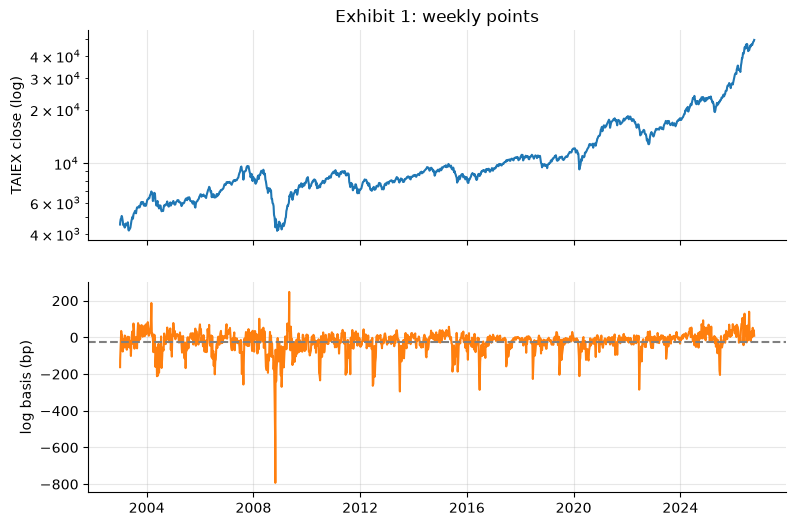

In [4]:
show("S first", S[0], ",.2f", "4,524.87")
show("S last", S[-1], ",.2f", "49,313.44")
show("growth", S[-1] / S[0], ".1f", "10.9")
show("mean basis (bp)", BP * b.mean(), ".1f", "-25.4")
show("s of the basis (bp)", BP * b.std(), ".1f", "58.2")
i_lo, i_hi = int(b.argmin()), int(b.argmax())
print("extremes:", dates[i_lo], round(BP * b[i_lo], 1), "|", dates[i_hi], round(BP * b[i_hi], 1))
show("s of rolled changes (bp)", BP * db.std(), ".1f", "38.9")


def rho_hat(x, k):
    c = x - x.mean()
    return float(c[k:] @ c[:-k] / (c @ c))


show("next-day correlation", rho_hat(b, 1), ".3f", "0.776")

iso = [dt.date.fromisoformat(d).isocalendar()[:2] for d in dates]
last_of_week = {w: i for i, w in enumerate(iso)}
keep = sorted(set(last_of_week.values()) | {0, i_lo, i_hi, N - 1})
show("weekly points", len(keep), ",", "1,227")
t_axis = [dt.date.fromisoformat(dates[i]) for i in keep]
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].semilogy(t_axis, S[keep])
ax[0].set_ylabel("TAIEX close (log)")
ax[1].plot(t_axis, BP * b[keep], color="C1")
ax[1].axhline(BP * b.mean(), ls="--", color="grey")
ax[1].set_ylabel("log basis (bp)")
ax[0].set_title("Exhibit 1: weekly points")
plt.show()

## Part 3 — Stationarity

Example 1 splits TX23 at 1 June 2015, when TWSE's daily price limit widened from 7% to 10%. A window's statistics use its own dates only. Then a simulated random walk and a stationary AR(1) with the same innovations show why a level has no fixed variance (seed `[101, 20261011]`, an illustration that the module does not print).

before 1 June 2015: 3078 dates, mean S 7,302, mean b -28.6 bp, s(b) 65.7 bp
from 1 June 2015: 2772 dates, mean S 16,042, mean b -21.8 bp, s(b) 48.2 bp
mean S before: 7,302   [book: 7,302]
mean S from: 16,042   [book: 16,042]
s(b) before: 65.7   [book: 65.7]
s(b) from: 48.2   [book: 48.2]


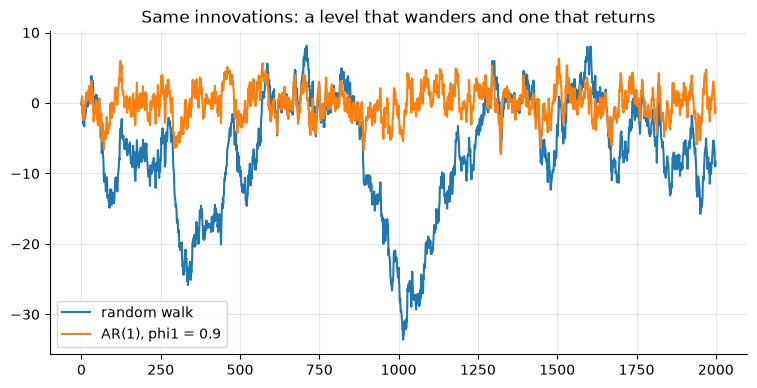

KC: AR(1) stationary sd (%): 2.753   [book: 2.753]


In [5]:
for name, msk in (("before", pre), ("from", ~pre)):
    print(f"{name} 1 June 2015: {int(msk.sum())} dates, mean S {S[msk].mean():,.0f}, "
          f"mean b {BP * b[msk].mean():.1f} bp, s(b) {BP * b[msk].std():.1f} bp")
show("mean S before", S[pre].mean(), ",.0f", "7,302")
show("mean S from", S[~pre].mean(), ",.0f", "16,042")
show("s(b) before", BP * b[pre].std(), ".1f", "65.7")
show("s(b) from", BP * b[~pre].std(), ".1f", "48.2")

rng = np.random.default_rng([101, SEED])
eta = rng.standard_normal(2000)
walk = np.cumsum(eta)
ar = np.zeros(2000)
for t in range(1, 2000):
    ar[t] = 0.9 * ar[t - 1] + eta[t]
plt.plot(walk, label="random walk")
plt.plot(ar, label="AR(1), phi1 = 0.9")
plt.legend(); plt.title("Same innovations: a level that wanders and one that returns"); plt.show()
show("KC: AR(1) stationary sd (%)", 1.2 / math.sqrt(1 - 0.81), ".3f", "2.753")

## Part 4 — AR and MA models

Example 2 regresses $b_t$ on a constant and $b_{t-1}$: first by hand from the normal equations, then with statsmodels' OLS. The partial autocorrelation at lag $k$ is the last coefficient of an OLS regression on lags 1 to $k$; `pacf(method="ols")` gives the same numbers (Exhibit 2).

In [6]:
def ols(X, y):
    beta = np.linalg.solve(X.T @ X, X.T @ y)
    e = y - X @ beta
    s2 = float(e @ e) / (len(y) - X.shape[1])
    return beta, np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X))), e


bb = BP * b
X = np.column_stack([np.ones(N - 1), bb[:-1]])
beta, se, e = ols(X, bb[1:])
c_hat, phi_hat = beta
half = math.log(0.5) / math.log(phi_hat)
show("c (bp)", c_hat, ".2f", "-5.66")
show("phi_hat", phi_hat, ".4f", "0.7758")
show("classical SE", se[1], ".5f", "0.00824")
show("s_eps (bp)", math.sqrt(float(e @ e) / (N - 1 - 2)), ".1f", "36.7")
show("half-life", half, ".2f", "2.73")
show("implied mean (bp)", c_hat / (1 - phi_hat), ".2f", "-25.25")

import statsmodels.api as sm
fit = sm.OLS(bb[1:], X).fit()
print("statsmodels:", fit.params, fit.bse)
assert np.allclose(fit.params, beta) and np.allclose(fit.bse, se)

# partial autocorrelations by regression, against pacf(method="ols")
pac_hand = []
for k in range(1, 21):
    Xk = np.column_stack([np.ones(N - k)] + [b[k - j:N - j] for j in range(1, k + 1)])
    pac_hand.append(ols(Xk, b[k:])[0][-1])
pac = pacf(b, nlags=20, method="ols")[1:]
assert np.allclose(pac_hand, pac)
acf_b = acf(b, nlags=20, fft=False)[1:]
print("ACF :", np.round(acf_b[:5], 3), "... lag 10", round(acf_b[9], 3), "lag 20", round(acf_b[19], 3))
print("PACF:", np.round(pac[:5], 3), "max beyond lag 5", round(float(np.abs(pac[5:]).max()), 3))
show("PACF lag 2", pac[1], ".3f", "0.230")
show("PACF lag 3", pac[2], ".3f", "0.109")

c (bp): -5.66   [book: -5.66]
phi_hat: 0.7758   [book: 0.7758]
classical SE: 0.00824   [book: 0.00824]
s_eps (bp): 36.7   [book: 36.7]
half-life: 2.73   [book: 2.73]
implied mean (bp): -25.25   [book: -25.25]
statsmodels: [-5.6603309  0.7758158] [0.52307589 0.00824232]
ACF : [0.776 0.693 0.633 0.569 0.536] ... lag 10 0.441 lag 20 0.36
PACF: [0.776 0.23  0.109 0.021 0.072] max beyond lag 5 0.065
PACF lag 2: 0.230   [book: 0.230]
PACF lag 3: 0.109   [book: 0.109]


## Part 5 — Tests for autocorrelation

Example 3 compares the iid band with the robust standard error (25.4); Exhibit 3 does it for 30 lags. Example 4 adds Ljung–Box (25.5) and the variance-ratio test (25.6) on LM19's overlapping $\operatorname{VR}(m)$. Problems 6 and 12 redo the arithmetic from the printed, rounded inputs.

rho_1: 0.0393   [book: 0.0393]
iid SE: 0.013076   [book: 0.013076]
robust SE lag 1: 0.0205   [book: 0.0205]
iid t-stat: 3.01   [book: 3.01]
robust t-stat: 1.92   [book: 1.92]
outside the iid band: [1, 4, 6, 8, 13, 14, 18, 20, 26] | outside the robust band: [8, 14]


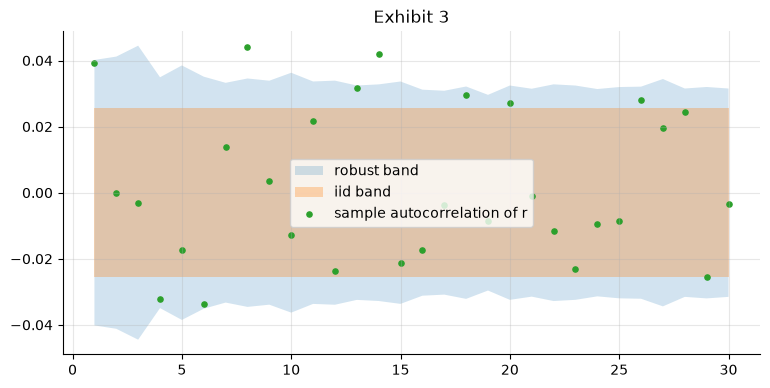

In [7]:
def se_rob(x, k):
    c = x - x.mean()
    return math.sqrt(float((c[k:] ** 2 * c[:-k] ** 2).sum())) / float(c @ c)


rho = np.array([rho_hat(r, k) for k in range(1, 31)])
rob = np.array([se_rob(r, k) for k in range(1, 31)])
assert np.allclose(rho, acf(r, nlags=30, fft=False)[1:])
se_iid = 1 / math.sqrt(T)
show("rho_1", rho[0], ".4f", "0.0393")
show("iid SE", se_iid, ".6f", "0.013076")
show("robust SE lag 1", rob[0], ".4f", "0.0205")
show("iid t-stat", rho[0] / se_iid, ".2f", "3.01")
show("robust t-stat", rho[0] / rob[0], ".2f", "1.92")
out_iid = [k for k in range(1, 31) if abs(rho[k - 1]) > 1.96 * se_iid]
out_rob = [k for k in range(1, 31) if abs(rho[k - 1]) > 1.96 * rob[k - 1]]
print("outside the iid band:", out_iid, "| outside the robust band:", out_rob)
assert len(out_iid) == 9 and out_rob == [8, 14]

lags = np.arange(1, 31)
plt.fill_between(lags, -1.96 * rob, 1.96 * rob, alpha=0.2, label="robust band")
plt.fill_between(lags, -1.96 * se_iid, 1.96 * se_iid, alpha=0.3, label="iid band")
plt.scatter(lags, rho, s=14, label="sample autocorrelation of r")
plt.legend(); plt.title("Exhibit 3"); plt.show()

In [8]:
lb = acorr_ljungbox(r, lags=[10]).to_numpy()          # a DataFrame: [[Q, p-value]]
q_hand = T * (T + 2) * sum(rho[k] ** 2 / (T - k - 1) for k in range(10))
assert abs(q_hand - lb[0, 0]) < 1e-8
show("Q_LB(10)", lb[0, 0], ".1f", "37.1")
print(f"p-value {lb[0, 1]:.1e}; chi2_10 5% point {stats.chi2.isf(0.05, 10):.2f}")
show("|r|: Q_LB(10)", acorr_ljungbox(np.abs(r), lags=[10]).to_numpy()[0, 0], ",.0f", "1,820")


def vr(x, m):     # LM19's (19.8): overlapping m-day sums centred at m * mean
    cs = np.concatenate([[0.0], np.cumsum(x)])
    sums = cs[m:] - cs[:-m]
    return float(((sums - m * x.mean()) ** 2).mean()) / (m * float(((x - x.mean()) ** 2).mean()))


for m in (2, 5, 10, 20):
    w = 2 * (1 - np.arange(1, m) / m)
    se_i = math.sqrt(2 * (2 * m - 1) * (m - 1) / (3 * m * T))
    se_r = math.sqrt(float((w ** 2) @ (rob[: m - 1] ** 2)))
    v = vr(r, m)
    print(f"m = {m:2d}: VR {v:.4f}, t iid {(v - 1) / se_i:.2f}, t robust {(v - 1) / se_r:.2f}")
show("VR(2) t iid", (vr(r, 2) - 1) / math.sqrt(2 * 3 * 1 / (3 * 2 * T)), ".2f", "3.00")

Q_LB(10): 37.1   [book: 37.1]
p-value 5.4e-05; chi2_10 5% point 18.31
|r|: Q_LB(10): 1,820   [book: 1,820]
m =  2: VR 1.0392, t iid 3.00, t robust 1.91
m =  5: VR 1.0465, t iid 1.62, t robust 1.02
m = 10: VR 1.0065, t iid 0.15, t robust 0.09
m = 20: VR 1.0359, t iid 0.55, t robust 0.37
VR(2) t iid: 3.00   [book: 3.00]


In [9]:
# Problem 6: Ljung-Box and robust t-stats from the printed four-decimal inputs
rho4 = [0.0393, 0.0000, -0.0031, -0.0323, -0.0173]
rob4 = [0.0205, 0.0210, 0.0227, 0.0178, 0.0196]
assert rho4 == [round(x, 4) + 0.0 for x in rho[:5]] and rob4 == [round(x, 4) for x in rob[:5]]
q5 = T * (T + 2) * sum(rho4[k] ** 2 / (T - k - 1) for k in range(5))
show("P6 Q_LB(5) from printed inputs", q5, ".2f", "16.96")
show("P6 Q_LB(5) unrounded", acorr_ljungbox(r, lags=[5]).to_numpy()[0, 0], ".2f", "16.98")
print("P6 robust t-stats:", [f"{a / c:.2f}" for a, c in zip(rho4, rob4)], "| chi2_5 5% point",
      f"{stats.chi2.isf(0.05, 5):.2f}")

# Problem 12: VR(5), iid and robust t-stats (robust SEs of Problem 6)
v5 = vr(r, 5)
se_i5 = math.sqrt(72 / (15 * 5849))
se_r5 = math.sqrt(sum((2 * (1 - k / 5)) ** 2 * rob4[k - 1] ** 2 for k in range(1, 5)))
show("P12 VR(5)", v5, ".4f", "1.0465")
show("P12 iid SE", se_i5, ".5f", "0.02865")
show("P12 t iid", (v5 - 1) / se_i5, ".2f", "1.62")
show("P12 robust SE", se_r5, ".5f", "0.04573")
show("P12 t robust", (v5 - 1) / se_r5, ".2f", "1.02")

P6 Q_LB(5) from printed inputs: 16.96   [book: 16.96]
P6 Q_LB(5) unrounded: 16.98   [book: 16.98]
P6 robust t-stats: ['1.92', '0.00', '-0.14', '-1.81', '-0.88'] | chi2_5 5% point 11.07
P12 VR(5): 1.0465   [book: 1.0465]
P12 iid SE: 0.02865   [book: 0.02865]
P12 t iid: 1.62   [book: 1.62]
P12 robust SE: 0.04573   [book: 0.04573]
P12 t robust: 1.02   [book: 1.02]


## Part 6 — Unit roots

Experiment 1 simulates the Dickey–Fuller null (Example 5, Exhibit 4): random walks $x_t=z_1+\dots+z_t$ of 5,850 levels, drawn in chunks of 500, each with the DF t-stat of (25.7) (constant, no lags, classical standard error). Example 6 then runs `adfuller` and `kpss` on $\ln S_t$ and $b_t$. Problem 10 repeats experiment 1's idea on one year of 246 levels.

1%, 5%, 10% points: [-3.44 -2.86 -2.58]
exp 1: 5% point: -2.86   [book: -2.86]
exp 1: batch SE: 0.014   [book: 0.014]
exp 1: mean: -1.54   [book: -1.54]
exp 1: share below -1.645 (%): 46.7   [book: 46.7]
MacKinnon for 5,849 observations: {'1%': np.float64(-3.43), '5%': np.float64(-2.86), '10%': np.float64(-2.57)}


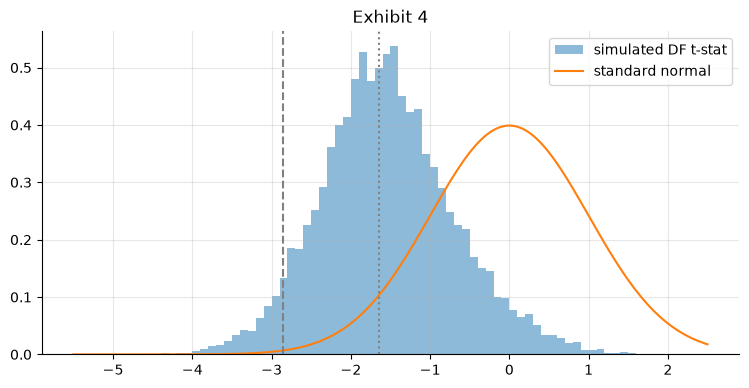

In [10]:
def df_tstats(e, length, n):
    rng = np.random.default_rng([e, SEED])
    out = np.empty(n)
    for c0 in range(0, n, 500):
        x = np.cumsum(rng.standard_normal((500, length)), axis=1)
        dy, xl = np.diff(x, axis=1), x[:, :-1]
        xm, ym = xl - xl.mean(axis=1, keepdims=True), dy - dy.mean(axis=1, keepdims=True)
        sxx = (xm * xm).sum(axis=1)
        d = (xm * ym).sum(axis=1) / sxx
        s2 = ((ym - d[:, None] * xm) ** 2).sum(axis=1) / (length - 3)
        out[c0:c0 + 500] = d / np.sqrt(s2 / sxx)
    return out


def batch_se(x, fn):
    vals = np.array([fn(p) for p in np.split(x, 20)])
    return float(vals.std(ddof=0) / math.sqrt(20))


def q05(x):
    return float(np.quantile(x, 0.05, method="inverted_cdf"))


t1 = df_tstats(1, 5850, 10_000)
print("1%, 5%, 10% points:", np.round(np.quantile(t1, [0.01, 0.05, 0.10], method="inverted_cdf"), 2))
show("exp 1: 5% point", q05(t1), ".2f", "-2.86")
show("exp 1: batch SE", batch_se(t1, q05), ".3f", "0.014")
show("exp 1: mean", t1.mean(), ".2f", "-1.54")
show("exp 1: share below -1.645 (%)", 100 * (t1 < -1.645).mean(), ".1f", "46.7")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    a0 = adfuller(b, maxlag=0, autolag=None, result_object=True)
print("MacKinnon for 5,849 observations:", {k: round(v, 2) for k, v in a0.critical_values.items()})
edges = np.arange(-55, 26) / 10
plt.hist(t1, bins=edges, density=True, alpha=0.5, label="simulated DF t-stat")
z = np.linspace(-5.5, 2.5, 200)
plt.plot(z, stats.norm.pdf(z), label="standard normal")
plt.axvline(q05(t1), ls="--", color="grey"); plt.axvline(-1.645, ls=":", color="grey")
plt.legend(); plt.title("Exhibit 4"); plt.show()

In [11]:
lnS = np.log(S)
X1 = np.column_stack([np.ones(N - 1), lnS[:-1]])
beta_s, se_s, _ = ols(X1, np.diff(lnS))
show("ln S: DF t by hand", beta_s[1] / se_s[1], ".2f", "1.19")
show("ln S: phi_hat", 1 + beta_s[1], ".6f", "1.000392")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    a_s = adfuller(lnS, regression="ct", autolag="AIC", result_object=True)
    k_s = kpss(lnS, regression="c", nlags="auto", result_object=True)
    a_b = adfuller(b, regression="c", autolag="AIC", result_object=True)
    k_b = kpss(b, regression="c", nlags="auto", result_object=True)
show("ln S: ADF 'ct'", a_s.statistic, ".2f", "-0.77")
print("ln S: ADF p-value", round(a_s.pvalue, 2), "with", a_s.lags, "lags; KPSS", round(k_s.statistic, 3), "p", k_s.pvalue)
show("b: ADF 'c'", a_b.statistic, ".2f", "-9.00")
print("b: ADF lags", a_b.lags, "p-value", f"{a_b.pvalue:.1e}")
show("b: KPSS", k_b.statistic, ".3f", "0.664")
show("b: KPSS p-value", k_b.pvalue, ".3f", "0.017")

# Problem 9: the DF regression by hand, rolled and roll-free
Xb = np.column_stack([np.ones(N - 1), b[:-1]])
beta_r, se_r, _ = ols(Xb, db)
beta_f, se_f, _ = ols(Xb, db_free)
show("P9 rolled t", beta_r[1] / se_r[1], ".2f", "-27.20")
show("P9 adfuller(maxlag=0)", a0.statistic, ".2f", "-27.20")
show("P9 roll-free t", beta_f[1] / se_f[1], ".2f", "-29.66")
show("P9 half-life rolled", math.log(0.5) / math.log(1 + beta_r[1]), ".2f", "2.73")
show("P9 half-life roll-free", math.log(0.5) / math.log(1 + beta_f[1]), ".2f", "2.72")

ln S: DF t by hand: 1.19   [book: 1.19]
ln S: phi_hat: 1.000392   [book: 1.000392]
ln S: ADF 'ct': -0.77   [book: -0.77]
ln S: ADF p-value 0.97 with 32 lags; KPSS 10.356 p 0.01
b: ADF 'c': -9.00   [book: -9.00]
b: ADF lags 28 p-value 6.6e-15
b: KPSS: 0.664   [book: 0.664]
b: KPSS p-value: 0.017   [book: 0.017]
P9 rolled t: -27.20   [book: -27.20]
P9 adfuller(maxlag=0): -27.20   [book: -27.20]
P9 roll-free t: -29.66   [book: -29.66]
P9 half-life rolled: 2.73   [book: 2.73]
P9 half-life roll-free: 2.72   [book: 2.72]


In [12]:
# Problem 10: experiment 3, one year of 246 levels, 100,000 walks
t3 = df_tstats(3, 246, 100_000)
show("P10 5% point", q05(t3), ".2f", "-2.87")
show("P10 batch SE", batch_se(t3, q05), ".3f", "0.006")
p3 = (t3 < -1.645).mean()
show("P10 share below -1.645 (%)", 100 * p3, ".1f", "45.7")
show("P10 its SE (%)", 100 * math.sqrt(p3 * (1 - p3) / 1e5), ".2f", "0.16")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    crit245 = adfuller(np.log(S[:246]), maxlag=0, autolag=None,       # any 246 levels: the points depend on nobs
                       result_object=True).critical_values["5%"]
show("P10 MacKinnon 5% for 245 observations", crit245, ".2f", "-2.87")

P10 5% point: -2.87   [book: -2.87]
P10 batch SE: 0.006   [book: 0.006]
P10 share below -1.645 (%): 45.7   [book: 45.7]
P10 its SE (%): 0.16   [book: 0.16]
P10 MacKinnon 5% for 245 observations: -2.87   [book: -2.87]


## Part 7 — Spurious regression and cointegration

Experiment 2 regresses one random walk on an independent one, 1,000 times (Example 7); its first pair is Exhibit 5. Example 8 estimates the cointegrating regression of $\ln F_t$ on $\ln S_t$, tests it with `coint`, and fits the error-correction regressions of the roll-free changes with White (HC0) standard errors. Problem 11 repeats experiment 2 on 246 sessions.

first pair: slope: 0.61   [book: 0.61]
first pair: t-stat: 23.5   [book: 23.5]
first pair: R-squared: 0.086   [book: 0.086]
first pair: t-stat on differences: -0.98   [book: -0.98]
share |t| > 1.96 (%): 96.6   [book: 96.6]
median |t|: 36   [book: 36]
median R-squared: 0.18   [book: 0.18]


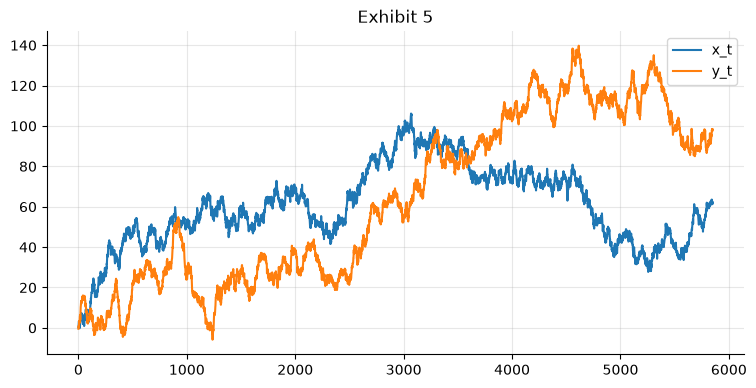

P11 share (%): 81.7   [book: 81.7]
P11 its SE (%): 1.2   [book: 1.2]
P11 median R-squared: 0.17   [book: 0.17]
P11 batch SE: 0.011   [book: 0.011]


In [13]:
def spurious(e, length, n):
    rng = np.random.default_rng([e, SEED])
    tt, r2, first = np.empty(n), np.empty(n), None
    for i in range(n):
        xy = np.cumsum(rng.standard_normal((2, length)), axis=1)     # x first, then y
        Xs = np.column_stack([np.ones(length), xy[0]])
        beta_, se_, e_ = ols(Xs, xy[1])
        tt[i] = beta_[1] / se_[1]
        r2[i] = 1 - float(e_ @ e_) / float(((xy[1] - xy[1].mean()) ** 2).sum())
        if i == 0:
            bd, sd, _ = ols(np.column_stack([np.ones(length - 1), np.diff(xy[0])]), np.diff(xy[1]))
            first = (beta_[1], tt[0], r2[0], bd[1] / sd[1], xy)
    return tt, r2, first


def med(x):
    return float(np.quantile(x, 0.5, method="inverted_cdf"))


tt2, r22, first = spurious(2, 5850, 1000)
show("first pair: slope", first[0], ".2f", "0.61")
show("first pair: t-stat", first[1], ".1f", "23.5")
show("first pair: R-squared", first[2], ".3f", "0.086")
show("first pair: t-stat on differences", first[3], ".2f", "-0.98")
show("share |t| > 1.96 (%)", 100 * (np.abs(tt2) > 1.96).mean(), ".1f", "96.6")
show("median |t|", med(np.abs(tt2)), ".0f", "36")
show("median R-squared", med(r22), ".2f", "0.18")
plt.plot(first[4][0], label="x_t"); plt.plot(first[4][1], label="y_t")
plt.legend(); plt.title("Exhibit 5"); plt.show()

tt4, r24, _ = spurious(4, 246, 1000)
p4 = (np.abs(tt4) > 1.96).mean()
show("P11 share (%)", 100 * p4, ".1f", "81.7")
show("P11 its SE (%)", 100 * math.sqrt(p4 * (1 - p4) / 1000), ".1f", "1.2")
show("P11 median R-squared", med(r24), ".2f", "0.17")
show("P11 batch SE", batch_se(r24, med), ".3f", "0.011")

In [14]:
lnF = np.log(F)
beta_eg, se_eg, e_eg = ols(np.column_stack([np.ones(N), lnS]), lnF)
show("EG intercept", beta_eg[0], ".4f", "-0.0283")
show("EG slope", beta_eg[1], ".4f", "1.0028")
show("EG residual rho_1", rho_hat(e_eg, 1), ".3f", "0.764")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cg = coint(lnF, lnS, trend="c", return_results=True)
show("coint t", cg.coint_t, ".2f", "-9.42")
print("coint p-value", f"{cg.pvalue:.1e}", "| 5% point", round(cg.critical_values[1], 2))


def hc0(X, e):
    xtxi = np.linalg.inv(X.T @ X)
    return np.sqrt(np.diag(xtxi @ ((X * e[:, None] ** 2).T @ X) @ xtxi))


bF, _, eF = ols(Xb, rF)
bS, _, eS = ols(Xb, rS)
show("alpha_F", bF[1], ".4f", "-0.1597")
show("alpha_F White SE", hc0(Xb, eF)[1], ".3f", "0.055")
show("alpha_S", bS[1], "+.4f", "+0.0655")
show("alpha_S White SE", hc0(Xb, eS)[1], ".3f", "0.040")
show("alpha_F - alpha_S = roll-free delta", bF[1] - bS[1], ".4f", "-0.2252")

EG intercept: -0.0283   [book: -0.0283]
EG slope: 1.0028   [book: 1.0028]
EG residual rho_1: 0.764   [book: 0.764]
coint t: -9.42   [book: -9.42]
coint p-value 7.4e-15 | 5% point -3.34
alpha_F: -0.1597   [book: -0.1597]
alpha_F White SE: 0.055   [book: 0.055]
alpha_S: +0.0655   [book: +0.0655]
alpha_S White SE: 0.040   [book: 0.040]
alpha_F - alpha_S = roll-free delta: -0.2252   [book: -0.2252]


## Part 8 — The basis as a time series

On sample D: convergence at expiry (Exhibit 6), roll jumps, the dividend season (Exhibit 7) and the four versions of Exhibit 8. Then Example 10: the ARMA(1,1) at the likelihood maximum, its standard errors from $-\ell''$ checked against a central-difference Hessian, the delta-method half-life, the sandwich, the regimes and 2025.

20 sessions before (235 dates): mean b -37.95, s 69.17, mean fair -14.78 bp
10 sessions before (284 dates): mean b -24.92, s 55.88, mean fair -5.58 bp
 2 sessions before (285 dates): mean b -6.56, s 35.13, mean fair -1.84 bp
20 sessions: mean: -37.95   [book: -37.95]
2 sessions: s: 35.13   [book: 35.13]


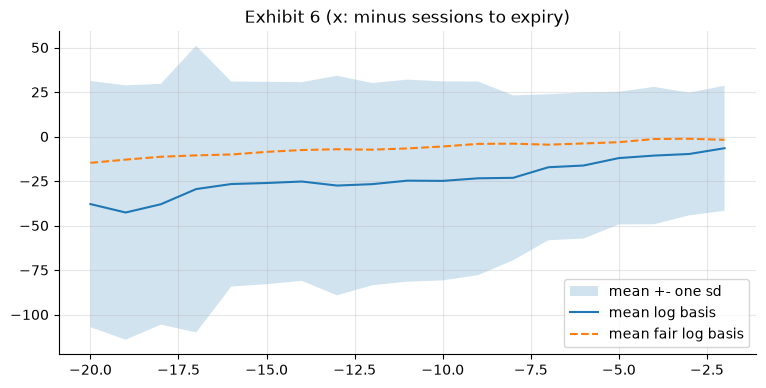

roll jumps: mean: -37.5   [book: -37.5]
June roll: -144.7   [book: -144.7]
July roll: -104.95   [book: -104.95]
shape: (12, 5)
┌───────┬────────────┬────────────┬────────────┬─────┐
│ month ┆ b          ┆ fair       ┆ resid      ┆ len │
│ ---   ┆ ---        ┆ ---        ┆ ---        ┆ --- │
│ i64   ┆ f64        ┆ f64        ┆ f64        ┆ u32 │
╞═══════╪════════════╪════════════╪════════════╪═════╡
│ 1     ┆ -6.11589   ┆ 9.852842   ┆ -15.968732 ┆ 451 │
│ 2     ┆ -14.880018 ┆ 8.231341   ┆ -23.111359 ┆ 369 │
│ 3     ┆ -19.908765 ┆ 7.155536   ┆ -27.064301 ┆ 532 │
│ 4     ┆ -10.552029 ┆ 9.158429   ┆ -19.710458 ┆ 477 │
│ 5     ┆ -17.432455 ┆ 0.204426   ┆ -17.636882 ┆ 503 │
│ 6     ┆ -74.797133 ┆ -67.429675 ┆ -7.367458  ┆ 498 │
│ 7     ┆ -70.173685 ┆ -65.880713 ┆ -4.292971  ┆ 524 │
│ 8     ┆ -39.18782  ┆ -15.648347 ┆ -23.539473 ┆ 522 │
│ 9     ┆ -14.727711 ┆ 4.521606   ┆ -19.249316 ┆ 481 │
│ 10    ┆ -16.142483 ┆ 9.541494   ┆ -25.683977 ┆ 476 │
│ 11    ┆ -10.644686 ┆ 8.098778   ┆ -18.743464 ┆

In [15]:
for k in (20, 10, 2):
    m_ = D & (sess == k)
    print(f"{k:2d} sessions before ({int(m_.sum())} dates): mean b {BP * b[m_].mean():.2f}, "
          f"s {BP * b[m_].std():.2f}, mean fair {BP * fair[m_].mean():.2f} bp")
show("20 sessions: mean", BP * b[D & (sess == 20)].mean(), ".2f", "-37.95")
show("2 sessions: s", BP * b[D & (sess == 2)].std(), ".2f", "35.13")
ks = np.arange(20, 1, -1)
mb = np.array([BP * b[D & (sess == k)].mean() for k in ks])
sb = np.array([BP * b[D & (sess == k)].std() for k in ks])
mf = np.array([BP * fair[D & (sess == k)].mean() for k in ks])
plt.fill_between(-ks, mb - sb, mb + sb, alpha=0.2, label="mean +- one sd")
plt.plot(-ks, mb, label="mean log basis"); plt.plot(-ks, mf, "--", label="mean fair log basis")
plt.legend(); plt.title("Exhibit 6 (x: minus sessions to expiry)"); plt.show()

jump = (db - db_free)[roll[1:]]
rmon = mon[1:][roll[1:]]
show("roll jumps: mean", BP * jump.mean(), ".1f", "-37.5")
show("June roll", BP * jump[rmon == 6].mean(), ".1f", "-144.7")
show("July roll", BP * jump[rmon == 7].mean(), ".2f", "-104.95")

season = pl.DataFrame({"month": mon[D], "b": BP * b[D], "fair": BP * fair[D], "resid": BP * resid[D]})
by_month = season.group_by("month").agg(pl.col("b", "fair", "resid").mean(), pl.len()).sort("month")
print(by_month)
show("June mean b", by_month.filter(pl.col("month") == 6)["b"][0], ".2f", "-74.80")
show("June fair", by_month.filter(pl.col("month") == 6)["fair"][0], ".2f", "-67.43")
show("D: carry", BP * (RF * tau[D]).mean(), "+.2f", "+9.73")
show("D: dividends", -BP * qt[D].mean(), ".2f", "-17.54")
show("D: residual", BP * resid[D].mean(), ".2f", "-17.76")

In [16]:
def arma_fit(x, strict=True):
    # ARMA(1,1) at the likelihood maximum: innovations MLE, then a restart that must not raise the log-likelihood
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(x, order=(1, 0, 1))
        f0 = model.fit(method="innovations_mle")
        f1 = model.fit(start_params=f0.params, cov_type="approx")
        default = model.fit()
    if strict:
        assert f1.llf - f0.llf < 1e-6 and f1.llf >= default.llf - 1e-9
    return model, f1, default


def half_life(phi):
    return math.log(0.5) / math.log(phi)


mb_month = {mm: b[D & (mon == mm)].mean() for mm in range(1, 13)}
versions = {"b": b[D], "b - carry": (b - RF * tau)[D], "residual": resid[D],
            "b - month mean": (b - np.array([mb_month[mm] for mm in mon]))[D]}
for name, x in versions.items():
    xb = BP * x
    Xv = np.column_stack([np.ones(len(x) - 1), x[:-1]])
    bv, sv, _ = ols(Xv, np.diff(x))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        av = adfuller(x, regression="c", autolag="AIC", result_object=True)
        kv = kpss(x, regression="c", nlags="auto", result_object=True)
    _, fv, _ = arma_fit(xb)
    print(f"{name:15s} mean {xb.mean():6.1f}  s {xb.std():6.2f}  DF {bv[1] / sv[1]:6.1f}  ADF {av.statistic:6.2f} "
          f"({av.lags})  KPSS {kv.statistic:.2f} (p {kv.pvalue:.3f})  AR {1 + bv[1]:.4f} "
          f"({half_life(1 + bv[1]):.2f})  ARMA {fv.params[1]:.5f}, {fv.params[2]:.3f} ({half_life(fv.params[1]):.2f})")

b               mean  -25.6  s  58.11  DF  -27.2  ADF  -9.03 (28)  KPSS 0.62 (p 0.021)  AR 0.7751 (2.72)  ARMA 0.90584, -0.355 (7.01)
b - carry       mean  -35.3  s  59.11  DF  -27.4  ADF  -9.15 (28)  KPSS 0.62 (p 0.021)  AR 0.7723 (2.68)  ARMA 0.89557, -0.327 (6.28)
residual        mean  -17.8  s  47.67  DF  -32.3  ADF  -7.75 (33)  KPSS 0.77 (p 0.010)  AR 0.6974 (1.92)  ARMA 0.89075, -0.414 (5.99)
b - month mean  mean   -0.0  s  53.24  DF  -30.3  ADF  -8.51 (28)  KPSS 0.96 (p 0.010)  AR 0.7284 (2.19)  ARMA 0.87168, -0.323 (5.05)


In [17]:
model, fit_b, default = arma_fit(BP * b)
p, se_p = fit_b.params, fit_b.bse
show("llf gap of the default fit", fit_b.llf - default.llf, ".3f", "0.006")
show("mean", p[0], ".1f", "-25.5")
show("phi1", p[1], ".5f", "0.90620")
show("SE(phi1), -l''", se_p[1], ".6f", "0.007055")
show("theta1", p[2], ".4f", "-0.3553")
show("sigma2 (bp^2)", p[3], ",.1f", "1,257.0")

# -l'' by hand: a central-difference Hessian of the log-likelihood
h = 1e-5 * np.maximum(1.0, np.abs(p))
H = np.empty((4, 4))
for i in range(4):
    for j in range(4):
        def ll(si, sj):
            q = p.copy(); q[i] += si * h[i]; q[j] += sj * h[j]
            return float(model.loglike(q))
        H[i, j] = (ll(1, 1) - ll(1, -1) - ll(-1, 1) + ll(-1, -1)) / (4 * h[i] * h[j])
se_hand = np.sqrt(np.diag(np.linalg.inv(-H)))
print("SEs, statsmodels approx:", np.round(se_p, 6), "| by hand:", np.round(se_hand, 6))
assert np.allclose(se_hand, se_p, rtol=1e-3)

# (25.9): a persistent AR(1) plus one-day noise
phi, theta, s2 = p[1], p[2], p[3]
su2 = -theta * s2 / phi
sz2 = (1 + theta ** 2) * s2 - (1 + phi ** 2) * su2
sx2 = sz2 / (1 - phi ** 2)
var_change = 2 * sx2 * (1 - phi) + 2 * su2
show("sigma_u (bp)", math.sqrt(su2), ".1f", "22.2")
show("sigma_zeta (bp)", math.sqrt(sz2), ".1f", "22.8")
show("persistent sd (bp)", math.sqrt(sx2), ".1f", "53.8")
show("noise share of a day's change (%)", 100 * 2 * su2 / var_change, ".0f", "64")
show("model sd of a change (bp)", math.sqrt(var_change), ".2f", "39.11")

hl = half_life(phi)
hl_se = abs(math.log(0.5) / (phi * math.log(phi) ** 2)) * se_p[1]
show("half-life", hl, ".2f", "7.04")
show("delta-method SE", hl_se, ".3f", "0.556")
print(f"95% interval {hl - 1.96 * hl_se:.2f} to {hl + 1.96 * hl_se:.2f}")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    se_sand = model.smooth(p, cov_type="robust_approx").bse
    se_opg = model.smooth(p, cov_type="opg").bse
    se_oim = model.smooth(p, cov_type="oim").bse
show("sandwich SE(phi1)", se_sand[1], ".5f", "0.01462")
show("'opg' SE(phi1)", se_opg[1], ".5f", "0.00385")
show("'oim' SE(phi1)", se_oim[1], ".4f", "0.0068")
hs = abs(math.log(0.5) / (phi * math.log(phi) ** 2)) * se_sand[1]
print(f"sandwich interval {hl - 1.96 * hs:.2f} to {hl + 1.96 * hs:.2f}")

llf gap of the default fit: 0.006   [book: 0.006]
mean: -25.5   [book: -25.5]
phi1: 0.90620   [book: 0.90620]
SE(phi1), -l'': 0.007055   [book: 0.007055]
theta1: -0.3553   [book: -0.3553]
sigma2 (bp^2): 1,257.0   [book: 1,257.0]
SEs, statsmodels approx: [3.1811130e+00 7.0550000e-03 1.6547000e-02 2.3241842e+01] | by hand: [3.1809310e+00 7.0550000e-03 1.6547000e-02 2.3241852e+01]
sigma_u (bp): 22.2   [book: 22.2]
sigma_zeta (bp): 22.8   [book: 22.8]
persistent sd (bp): 53.8   [book: 53.8]
noise share of a day's change (%): 64   [book: 64]
model sd of a change (bp): 39.11   [book: 39.11]
half-life: 7.04   [book: 7.04]
delta-method SE: 0.556   [book: 0.556]
95% interval 5.95 to 8.13
sandwich SE(phi1): 0.01462   [book: 0.01462]
'opg' SE(phi1): 0.00385   [book: 0.00385]
'oim' SE(phi1): 0.0068   [book: 0.0068]
sandwich interval 4.78 to 9.30


In [18]:
# stability check by limit regime, then 2025 alone (each window's changes within the window)
for name, msk in (("before 1 June 2015", pre), ("from 1 June 2015", ~pre), ("2025", yr == 2025)):
    x = b[msk]
    _, f_, _ = arma_fit(BP * x)
    ph, th, s2_ = f_.params[1], f_.params[2], f_.params[3]
    su = math.sqrt(-th * s2_ / ph)
    Xw = np.column_stack([np.ones(len(x) - 1), x[:-1]])
    bw, sw, _ = ols(Xw, np.diff(x))
    print(f"{name}: {len(x)} dates, DF t {bw[1] / sw[1]:.2f}, ARMA phi {ph:.4f} theta {th:.4f} sigma2 {s2_:.1f}, "
          f"sigma_u {su:.2f} bp")
m25 = yr == 2025
_, f25, _ = arma_fit(BP * b[m25])
su25 = math.sqrt(-f25.params[2] * f25.params[3] / f25.params[1])
show("2025 sigma_u (bp)", su25, ".1f", "23.4")
show("2025 sigma_u in index points", su25 / BP * S[m25].mean(), ".0f", "56")
show("2025 sd of daily changes (points)", np.diff(b[m25]).std() * S[m25].mean(), ".1f", "84.5")

# Problem 8: (25.9) from the regimes' estimates printed to four decimals
for ph, th, s2_ in ((0.9035, -0.3606, 1659.9), (0.9101, -0.3427, 808.6)):
    su2_ = -th * s2_ / ph
    sx2_ = ((1 + th ** 2) * s2_ - (1 + ph ** 2) * su2_) / (1 - ph ** 2)
    print(f"phi {ph}: sigma_u {math.sqrt(su2_):.2f} bp, persistent sd {math.sqrt(sx2_):.2f} bp, noise share "
          f"{100 * 2 * su2_ / (2 * sx2_ * (1 - ph) + 2 * su2_):.1f}%")

before 1 June 2015: 3078 dates, DF t -20.20, ARMA phi 0.9035 theta -0.3606 sigma2 1659.9, sigma_u 25.74 bp
from 1 June 2015: 2772 dates, DF t -17.88, ARMA phi 0.9101 theta -0.3427 sigma2 808.6, sigma_u 17.45 bp
2025: 243 dates, DF t -6.41, ARMA phi 0.9421 theta -0.5597 sigma2 921.1, sigma_u 23.39 bp
2025 sigma_u (bp): 23.4   [book: 23.4]
2025 sigma_u in index points: 56   [book: 56]
2025 sd of daily changes (points): 84.5   [book: 84.5]
phi 0.9035: sigma_u 25.74 bp, persistent sd 60.50 bp, noise share 65.2%
phi 0.9101: sigma_u 17.45 bp, persistent sd 44.95 bp, noise share 62.6%


## Part 9 — The module's Python block, and an extension

The block below is Section 8's code as printed, run on this notebook's arrays (`b`, `F`, `S`, `r`).

In [19]:
import numpy as np
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller, coint, kpss, pacf

rho = acf(r, nlags=30, fft=False)[1:]        # (19.5), divisor T
pac = pacf(b, nlags=20, method="ols")[1:]    # the default is "ywadjusted"
lb = acorr_ljungbox(r, lags=[10]).to_numpy() # [[Q_LB(10), p-value]]
a = adfuller(b, regression="c", autolag="AIC", result_object=True)
a0 = adfuller(b, maxlag=0, autolag=None, result_object=True)
k = kpss(b, regression="c", nlags="auto", result_object=True)
eg = coint(np.log(F), np.log(S), trend="c", return_results=True)
model = ARIMA(1e4 * b, order=(1, 0, 1))      # basis in bp; const = mean
f0 = model.fit(method="innovations_mle")
f = model.fit(start_params=f0.params, cov_type="approx")  # restart, -l''
print(a.statistic, a.lags, a0.statistic, f.params, f.bse)

-8.9984724011146 28 -27.199169697074485 [-2.54927320e+01  9.06200515e-01 -3.55290250e-01  1.25699492e+03] [3.18111321e+00 7.05530055e-03 1.65469383e-02 2.32418421e+01]


### Extension: the basis's half-lives year by year (stability check)

Fit the AR(1) by OLS and the ARMA(1,1) at the likelihood maximum to each calendar year's log basis, with changes within the year only. Does the persistent part's half-life drift with the years, and does the noise (25.9) follow the limit regimes? A year has about 246 sessions, so expect wide intervals; a year-by-year table is a stability check, not a test (LM34 tests on later data).

In [20]:
rows_y = []
for y in range(2003, 2027):
    x = BP * b[yr == y]
    Xy = np.column_stack([np.ones(len(x) - 1), x[:-1]])
    phi_y = ols(Xy, x[1:])[0][1]
    _, fy, _ = arma_fit(x, strict=False)
    rows_y.append({"year": y, "dates": len(x), "AR(1) phi": round(phi_y, 3),
                   "AR(1) half-life": round(half_life(phi_y), 2) if 0 < phi_y < 1 else None,
                   "ARMA phi": round(float(fy.params[1]), 3),
                   "ARMA half-life": round(half_life(fy.params[1]), 2) if 0 < fy.params[1] < 1 else None})
print(pl.DataFrame(rows_y))
# your code: add sigma_u by (25.9) to each row and plot it against the year

shape: (24, 6)
┌──────┬───────┬───────────┬─────────────────┬──────────┬────────────────┐
│ year ┆ dates ┆ AR(1) phi ┆ AR(1) half-life ┆ ARMA phi ┆ ARMA half-life │
│ ---  ┆ ---   ┆ ---       ┆ ---             ┆ ---      ┆ ---            │
│ i64  ┆ i64   ┆ f64       ┆ f64             ┆ f64      ┆ f64            │
╞══════╪═══════╪═══════════╪═════════════════╪══════════╪════════════════╡
│ 2003 ┆ 249   ┆ 0.601     ┆ 1.36            ┆ 0.888    ┆ 5.83           │
│ 2004 ┆ 250   ┆ 0.766     ┆ 2.6             ┆ 0.899    ┆ 6.52           │
│ 2005 ┆ 247   ┆ 0.784     ┆ 2.85            ┆ 0.878    ┆ 5.31           │
│ 2006 ┆ 248   ┆ 0.778     ┆ 2.76            ┆ 0.918    ┆ 8.1            │
│ 2007 ┆ 247   ┆ 0.575     ┆ 1.25            ┆ 0.946    ┆ 12.45          │
│ 2008 ┆ 249   ┆ 0.728     ┆ 2.18            ┆ 0.852    ┆ 4.33           │
│ 2009 ┆ 251   ┆ 0.657     ┆ 1.65            ┆ 0.795    ┆ 3.02           │
│ 2010 ┆ 251   ┆ 0.819     ┆ 3.47            ┆ 0.912    ┆ 7.55           │
│ 2011 ┆ 2